In [3]:
!sudo apt-get update && sudo apt-get install -y graphviz
!pip install graphviz


Get:1 http://deb.debian.org/debian trixie InRelease [140 kB]
Get:2 http://deb.debian.org/debian trixie-updates InRelease [47.3 kB]
Get:3 http://deb.debian.org/debian-security trixie-security InRelease [43.4 kB]
Get:4 http://deb.debian.org/debian trixie/main amd64 Packages [9678 kB]
Get:5 http://deb.debian.org/debian trixie-updates/main amd64 Packages [1108 B]
Get:6 http://deb.debian.org/debian-security trixie-security/main amd64 Packages [302 kB]
Fetched 10.2 MB in 1s (11.5 MB/s)                         
Reading package lists... Done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  fonts-liberation fonts-liberation-sans-narrow libabsl20240722 libann0
  libaom3 libavif16 libcdt5 libcgraph6 libgav1-1 libgd3 libgts-0.7-5t64
  libgts-bin libgvc6 libgvpr2 libimagequant0 liblab-gamut1 libpathplan4
  librav1e0.7 libsvtav1enc2 libxaw7 libxmu6 libxpm4 libyuv0
Suggested packages:
  gsfonts grap

# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [4]:
%%writefile heap.py
import graphviz
from IPython.display import display

class Heap:
    def __init__(self):
        self.arreglo = [float('-inf')]

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        indice_hijo = len(self.arreglo) - 1
        hijo = self.arreglo[indice_hijo]
        indice_padre = indice_hijo // 2
        padre = self.arreglo[indice_padre]

        while hijo < padre:
            self.arreglo[indice_hijo], self.arreglo[indice_padre] = (
                self.arreglo[indice_padre],
                self.arreglo[indice_hijo],
            )
            indice_hijo = indice_padre
            indice_padre = indice_hijo // 2
            hijo = self.arreglo[indice_hijo]
            padre = self.arreglo[indice_padre]
            
        if imagen:
            display(self._dibujar())

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) <= 1:
            raise IndexError("remove_smallest de un Heap vacío")

        minimo = self.arreglo[1]
        ultimo = self.arreglo.pop()

        if len(self.arreglo) > 1:
            self.arreglo[1] = ultimo
            i = 1
            n = len(self.arreglo) - 1

            while 2 * i <= n:
                hijo_izq = 2 * i
                hijo_der = 2 * i + 1
                menor = hijo_izq

                if hijo_der <= n and self.arreglo[hijo_der] < self.arreglo[hijo_izq]:
                    menor = hijo_der

                if self.arreglo[i] > self.arreglo[menor]:
                    self.arreglo[i], self.arreglo[menor] = (
                        self.arreglo[menor],
                        self.arreglo[i],
                    )
                    i = menor
                else:
                    break
                    
        if imagen:
            display(self._dibujar())

        return minimo

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        n = len(self.arreglo) - 1

        for inicio in range(n // 2, 0, -1):
            i = inicio
            while 2 * i <= n:
                hijo_izq = 2 * i
                hijo_der = 2 * i + 1
                menor = hijo_izq

                if hijo_der <= n and self.arreglo[hijo_der] < self.arreglo[hijo_izq]:
                    menor = hijo_der

                if self.arreglo[i] > self.arreglo[menor]:
                    self.arreglo[i], self.arreglo[menor] = (
                        self.arreglo[menor],
                        self.arreglo[i],
                    )
                    i = menor
                else:
                    break
                    
        if imagen:
            display(self._dibujar())
            
    def _dibujar(self):
        """Genera el árbol y retorna el objeto para poder guardarlo."""
        if len(self.arreglo) <= 1:
            return None

        dot = graphviz.Digraph()
        dot.attr('node', shape='circle', style='filled', fillcolor='lightblue')
        
        n = len(self.arreglo)
        for i in range(1, n):
            dot.node(str(i), str(self.arreglo[i]))
            if i > 1:
                dot.edge(str(i // 2), str(i))
                
        return dot

Overwriting heap.py


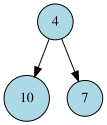

In [5]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

## 6. Prueba: 5 inserciones con fotos

Todos hacen **la misma prueba**: empezando con un heap vacío, inserte **en este orden** los valores

```python
[15, 8, 20, 3, 10]
```

con `imagen=True` en cada inserción, y guarde las **5 imágenes** (una después de cada inserción) como archivos PNG en la carpeta `fotos`, dentro de `student_work/Proyecto2`:

```
student_work/Proyecto2/
├── heap.py
└── fotos/
    ├── insert_1.png    # después de insertar 15
    ├── insert_2.png    # después de insertar 8
    ├── insert_3.png    # después de insertar 20
    ├── insert_4.png    # después de insertar 3
    └── insert_5.png    # después de insertar 10
```

- Use exactamente esos nombres de archivo y esa carpeta.
- Cada foto muestra el árbol del heap **completo** después de esa inserción.
- No olvide hacer *commit* y *push* de la carpeta `fotos`.

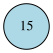

1 [-inf, 15]


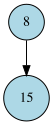

2 [-inf, 8, 15]


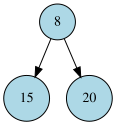

3 [-inf, 8, 15, 20]


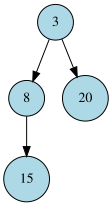

4 [-inf, 3, 8, 20, 15]


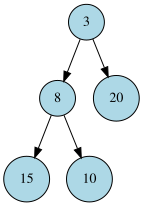

5 [-inf, 3, 8, 20, 15, 10]


In [7]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)  # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]         # NO cambie esta lista

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    grafo = H._dibujar()
    if grafo:
        # Renderiza y guarda automáticamente como PNG
        grafo.render(f"fotos/insert_{i}", format="png", cleanup=True)
        
    print(i, H.arreglo)